<a href="https://colab.research.google.com/github/FatimaZahraBoukab/DeepLearning-Lab1/blob/main/Lab1_DeepLearning_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q skorch imbalanced-learn kagglehub

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix,
                             classification_report, r2_score,
                             mean_squared_error, mean_absolute_error)
from skorch import NeuralNetRegressor, NeuralNetClassifier

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
torch.manual_seed(42); np.random.seed(42)

Device : cuda


In [4]:
import kagglehub
path = kagglehub.dataset_download("dgawlik/nyse")
print(path)
import os
print(os.listdir(path))

Using Colab cache for faster access to the 'nyse' dataset.
/kaggle/input/nyse
['prices-split-adjusted.csv', 'fundamentals.csv', 'prices.csv', 'securities.csv']


In [5]:
df = pd.read_csv(os.path.join(path, "prices-split-adjusted.csv"))
df['date'] = pd.to_datetime(df['date'])
df.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [6]:
print(df.shape)
df.info()
display(df.describe())
print("Valeurs manquantes :\n", df.isnull().sum())
print("Nombre d'actions :", df['symbol'].nunique())

(851264, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB


,date,open,close,low,high,volume
count,851264,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.993618,65.011913,64.336541,65.639748,5.415113e+06
min,2010-01-04 00:00:00,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,2011-10-19 00:00:00,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,2013-08-02 00:00:00,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,2015-04-24 00:00:00,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,2016-12-30 00:00:00,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08
std,NaN,75.203893,75.201216,74.459518,75.906861,1.249468e+07


Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64
Nombre d'actions : 501


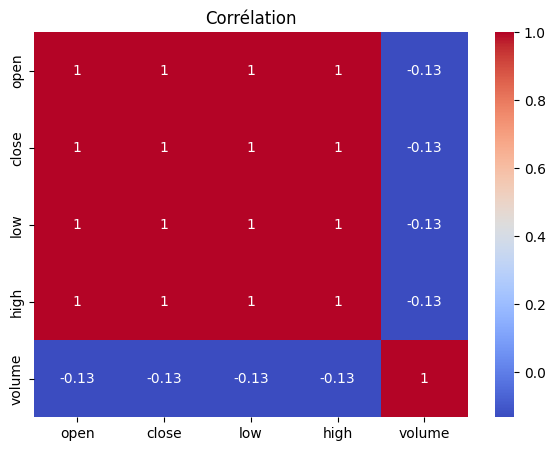

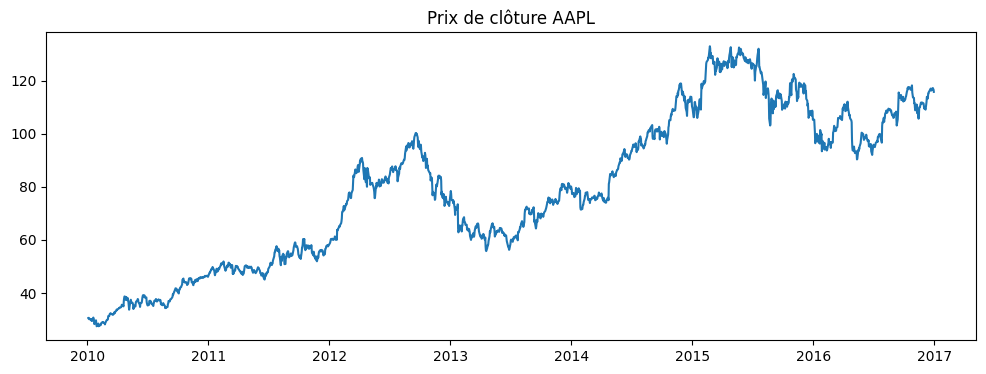

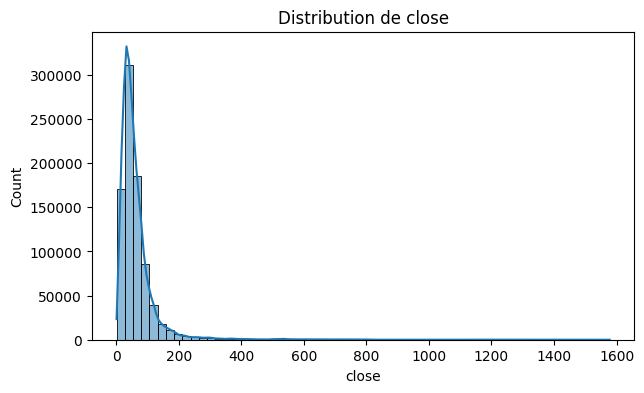

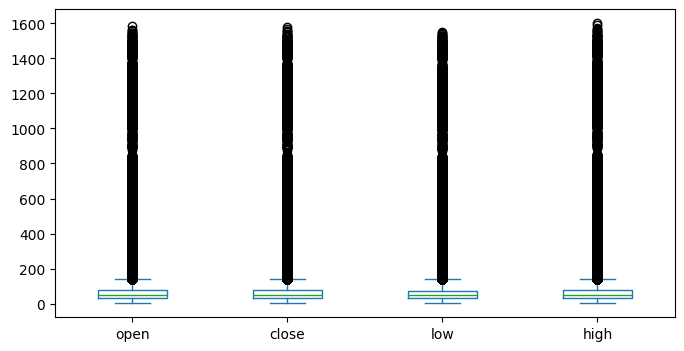

In [7]:
# Matrice de corrélation
plt.figure(figsize=(7,5))
sns.heatmap(df[['open','close','low','high','volume']].corr(), annot=True, cmap='coolwarm')
plt.title("Corrélation"); plt.show()

# Évolution d'une action (ex. AAPL)
aapl = df[df.symbol=='AAPL']
plt.figure(figsize=(12,4)); plt.plot(aapl['date'], aapl['close'])
plt.title("Prix de clôture AAPL"); plt.show()

# Distribution du prix de clôture
plt.figure(figsize=(7,4)); sns.histplot(df['close'], bins=60, kde=True)
plt.title("Distribution de close"); plt.show()

# Boxplots (valeurs aberrantes)
df[['open','close','low','high']].plot(kind='box', figsize=(8,4)); plt.show()

In [8]:
features = ['open','low','high','volume']
target = 'close'

# Pour éviter un entraînement trop lent, on peut échantillonner
data = df.sample(200000, random_state=42)

X = data[features].values.astype(np.float32)
y = data[target].values.astype(np.float32).reshape(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sx, sy = StandardScaler(), StandardScaler()
X_train = sx.fit_transform(X_train).astype(np.float32)
X_test  = sx.transform(X_test).astype(np.float32)
y_train = sy.fit_transform(y_train).astype(np.float32)
y_test  = sy.transform(y_test).astype(np.float32)

In [9]:
class MLPReg(nn.Module):
    def __init__(self, n_in=4, h1=64, h2=32, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h2, 1)
        )
    def forward(self, x):
        return self.net(x)

In [10]:
# Sous-échantillon pour le GridSearch uniquement
X_small = X_train[:40000]
y_small = y_train[:40000]

net = NeuralNetRegressor(
    MLPReg,
    criterion=nn.MSELoss,
    optimizer=optim.Adam,
    max_epochs=20,
    batch_size=1024,
    train_split=None,
    device=device,
    verbose=0,
)

params = {
    'lr': [0.001, 0.01],
    'optimizer': [optim.Adam, optim.SGD],
    'max_epochs': [20, 40],
    'module__h1': [32, 64],
    'module__h2': [32],
}

gs = GridSearchCV(net, params, cv=2, scoring='r2', n_jobs=1, verbose=1)
gs.fit(X_small, y_small)
print("Meilleurs paramètres :", gs.best_params_)
print("Meilleur R2 CV :", gs.best_score_)

Fitting 2 folds for each of 16 candidates, totalling 32 fits
Meilleurs paramètres : {'lr': 0.001, 'max_epochs': 40, 'module__h1': 32, 'module__h2': 32, 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur R2 CV : 0.9998336732387543


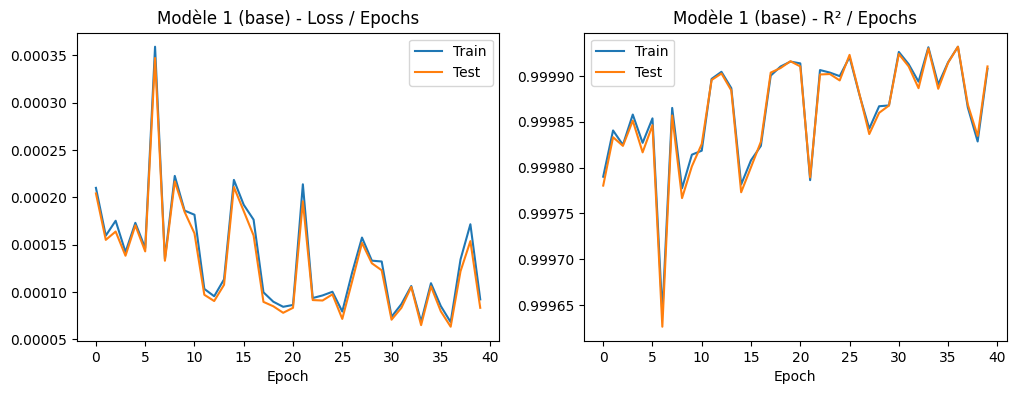

R2 train : 0.9999078424608104
R2 test  : 0.9999103730324387


In [11]:
bp = gs.best_params_

def train_reg(model, lr, opt_class, epochs, wd=0.0, patience=None):
    model = model.to(device)
    opt = opt_class(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.MSELoss()
    Xtr = torch.tensor(X_train).to(device); ytr = torch.tensor(y_train).to(device)
    Xte = torch.tensor(X_test).to(device);  yte = torch.tensor(y_test).to(device)
    hist = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}
    best, wait = 1e9, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            idx = perm[i:i+256]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            ptr, pte = model(Xtr), model(Xte)
            ltr, lte = loss_fn(ptr, ytr).item(), loss_fn(pte, yte).item()
            hist['train_loss'].append(ltr); hist['test_loss'].append(lte)
            hist['train_r2'].append(r2_score(ytr.cpu(), ptr.cpu()))
            hist['test_r2'].append(r2_score(yte.cpu(), pte.cpu()))
        if patience:
            if lte < best:
                best, wait = lte, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    return model, hist

def plot_hist(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['train_loss'], label='Train'); ax[0].plot(h['test_loss'], label='Test')
    ax[0].set_title(f'{title} - Loss / Epochs'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h['train_r2'], label='Train'); ax[1].plot(h['test_r2'], label='Test')
    ax[1].set_title(f'{title} - R² / Epochs'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()

m1 = MLPReg(4, bp['module__h1'], bp['module__h2'])
m1, h1 = train_reg(m1, bp['lr'], bp['optimizer'], bp['max_epochs'])
plot_hist(h1, "Modèle 1 (base)")
print("R2 train :", h1['train_r2'][-1])
print("R2 test  :", h1['test_r2'][-1])

In [12]:
class MLPRegReg(nn.Module):
    def __init__(self, n_in=4, h1=32, h2=32, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = [nn.Linear(n_in, h1)]
        if batchnorm: layers.append(nn.BatchNorm1d(h1))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h1, h2)]
        if batchnorm: layers.append(nn.BatchNorm1d(h2))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h2, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

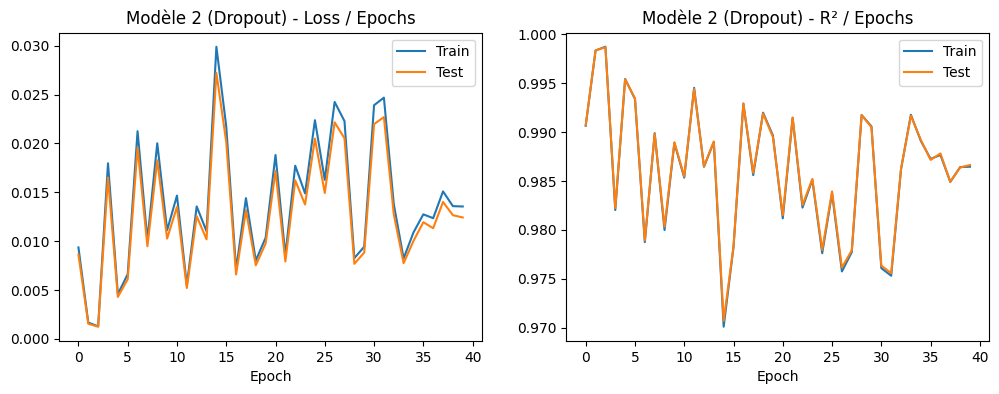

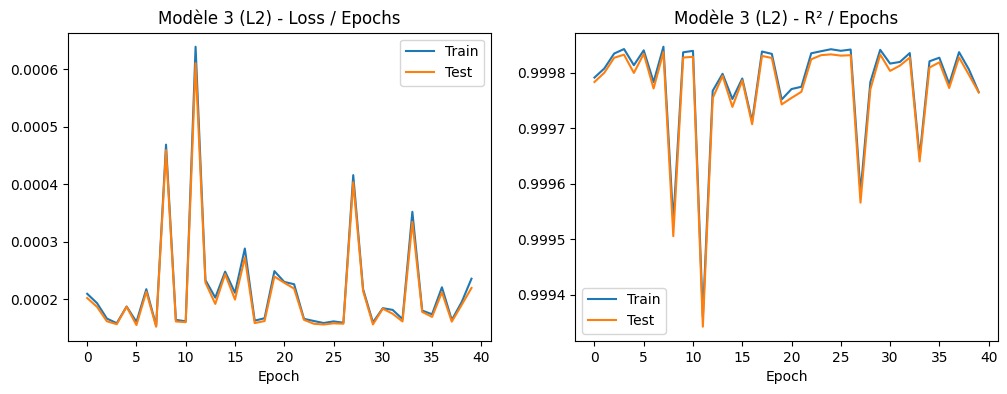

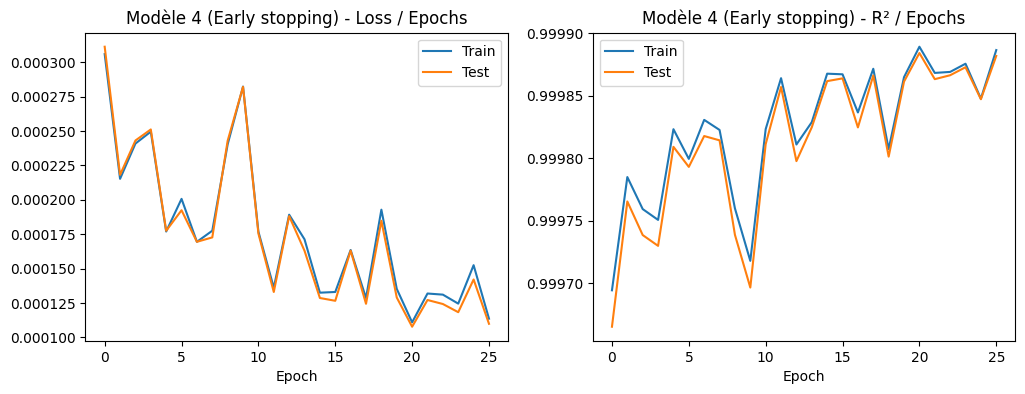

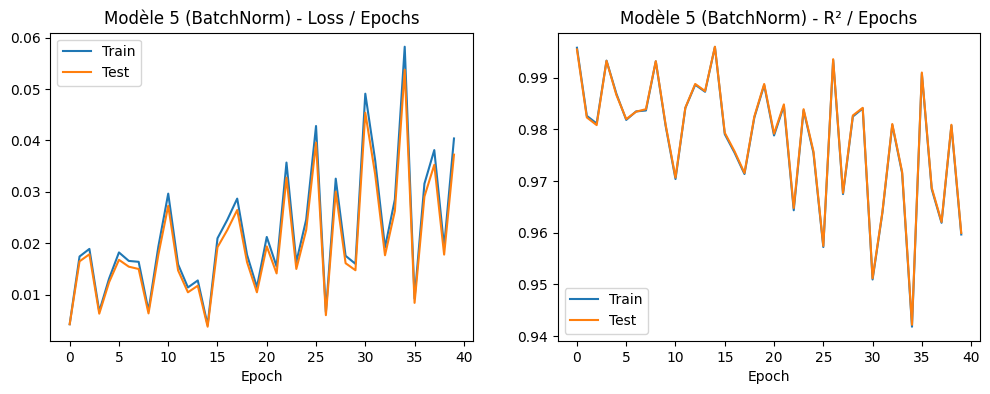

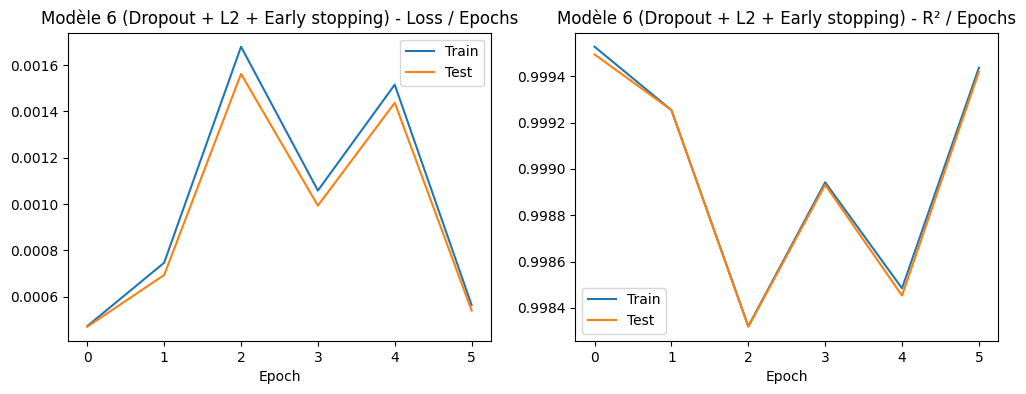

In [13]:
h1_, h2_ = bp['module__h1'], bp['module__h2']
lr, opt_c, ep = bp['lr'], bp['optimizer'], bp['max_epochs']

# Modèle 2 : Dropout seul
m2, hist2 = train_reg(MLPRegReg(4, h1_, h2_, dropout=0.2), lr, opt_c, ep)

# Modèle 3 : L2 (weight decay) seul
m3, hist3 = train_reg(MLPRegReg(4, h1_, h2_), lr, opt_c, ep, wd=1e-3)

# Modèle 4 : Early stopping seul
m4, hist4 = train_reg(MLPRegReg(4, h1_, h2_), lr, opt_c, 100, patience=5)

# Modèle 5 : BatchNorm seule
m5, hist5 = train_reg(MLPRegReg(4, h1_, h2_, batchnorm=True), lr, opt_c, ep)

# Modèle 6 : Combinaison Dropout + L2 + Early stopping
m6, hist6 = train_reg(MLPRegReg(4, h1_, h2_, dropout=0.1), lr, opt_c, 100, wd=1e-4, patience=5)

plot_hist(hist2, "Modèle 2 (Dropout)")
plot_hist(hist3, "Modèle 3 (L2)")
plot_hist(hist4, "Modèle 4 (Early stopping)")
plot_hist(hist5, "Modèle 5 (BatchNorm)")
plot_hist(hist6, "Modèle 6 (Dropout + L2 + Early stopping)")

,Modèle,Epochs,Loss train,Loss test,R² train,R² test,Écart R² (train-test)
0,Base (modèle 1),40,0.000092,0.000083,0.999908,0.999910,-0.000003
1,Dropout,40,0.013549,0.012426,0.986451,0.986625,-0.000174
2,L2,40,0.000235,0.000219,0.999765,0.999764,0.000001
3,Early stopping,26,0.000114,0.000110,0.999886,0.999882,0.000005
4,BatchNorm,40,0.040370,0.037222,0.959630,0.959936,-0.000306
5,Combiné,6,0.000564,0.000540,0.999436,0.999419,0.000017


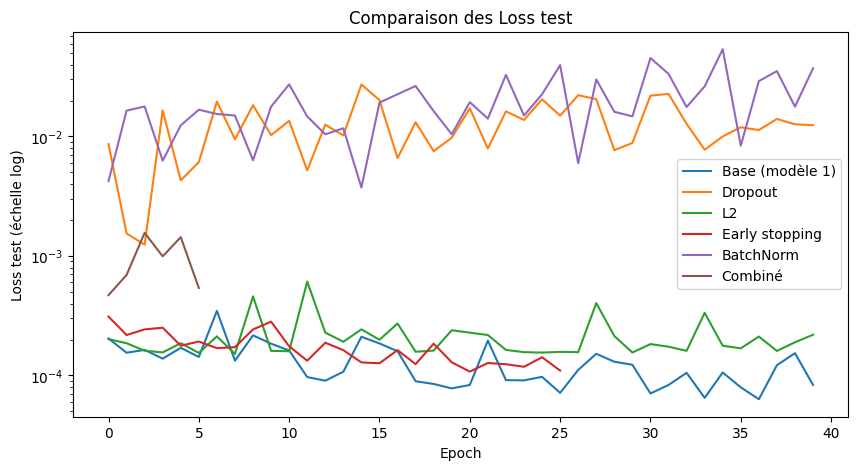

In [14]:
histories = {
    'Base (modèle 1)': h1,
    'Dropout': hist2,
    'L2': hist3,
    'Early stopping': hist4,
    'BatchNorm': hist5,
    'Combiné': hist6,
}

rows = []
for name, h in histories.items():
    rows.append({
        'Modèle': name,
        'Epochs': len(h['train_loss']),
        'Loss train': h['train_loss'][-1],
        'Loss test': h['test_loss'][-1],
        'R² train': h['train_r2'][-1],
        'R² test': h['test_r2'][-1],
        'Écart R² (train-test)': h['train_r2'][-1] - h['test_r2'][-1],
    })
comparaison = pd.DataFrame(rows).round(6)
display(comparaison)

plt.figure(figsize=(10, 5))
for name, h in histories.items():
    plt.plot(h['test_loss'], label=name)
plt.yscale('log')
plt.xlabel('Epoch'); plt.ylabel('Loss test (échelle log)')
plt.title('Comparaison des Loss test'); plt.legend(); plt.show()


# Partie 2 : Classification multiclasse (maintenance prédictive)

---



In [15]:
path2 = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
print(os.listdir(path2))

df2 = pd.read_csv(os.path.join(path2, "predictive_maintenance.csv"))
print(df2.shape)
print(df2.columns.tolist())
df2.head()

100%|██████████| 137k/137k [00:00<00:00, 51.9MB/s]

Extracting files...
['predictive_maintenance.csv']
(10000, 10)
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [16]:
# Aperçu qualité des données
df2.info()
print("Valeurs manquantes :\n", df2.isnull().sum())
print("Doublons :", df2.duplicated().sum())
print("\nDistribution des classes :\n", df2['Failure Type'].value_counts())

# 1. Colonnes d'identifiants, inutiles pour la prédiction
df2 = df2.drop(columns=['UDI', 'Product ID'])

# 2. Lignes incohérentes : Target=1 (panne) mais Failure Type = "No Failure"
incoh = df2[(df2['Target'] == 1) & (df2['Failure Type'] == 'No Failure')]
print("\nLignes incohérentes supprimées :", len(incoh))
df2 = df2.drop(incoh.index)

# 3. Target est la version binaire de Failure Type : on la retire pour éviter une fuite de données
df2 = df2.drop(columns=['Target'])

# 4. Encodage de la variable catégorielle Type (L, M, H)
df2['Type'] = LabelEncoder().fit_transform(df2['Type'])

# 5. Encodage de la cible multiclasse
le = LabelEncoder()
df2['label'] = le.fit_transform(df2['Failure Type'])
print("\nCorrespondance des classes :", dict(zip(le.classes_, le.transform(le.classes_))))

df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
Valeurs manquantes :
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational sp

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure Type,label
0,2,298.1,308.6,1551,42.8,0,No Failure,1
1,1,298.2,308.7,1408,46.3,3,No Failure,1
2,1,298.1,308.5,1498,49.4,5,No Failure,1
3,1,298.2,308.6,1433,39.5,7,No Failure,1
4,1,298.2,308.7,1408,40.0,9,No Failure,1


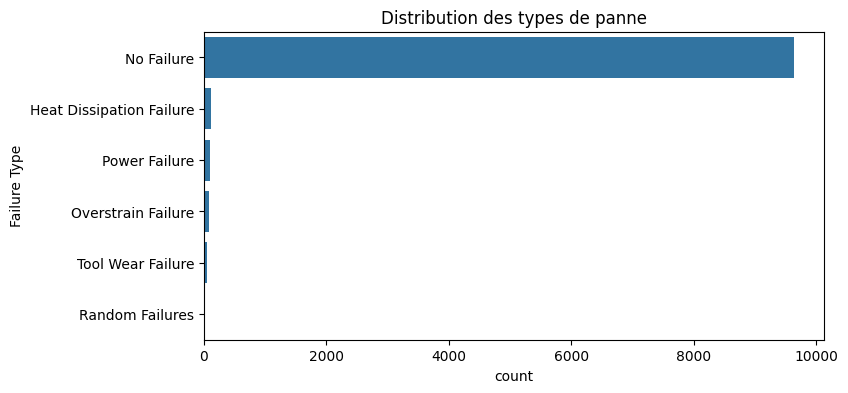

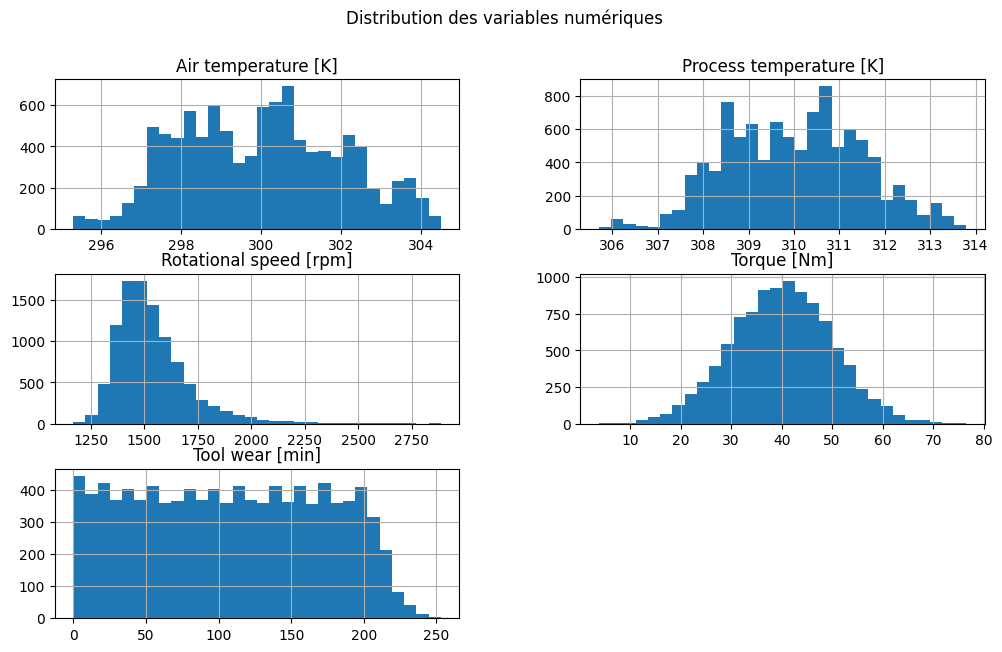

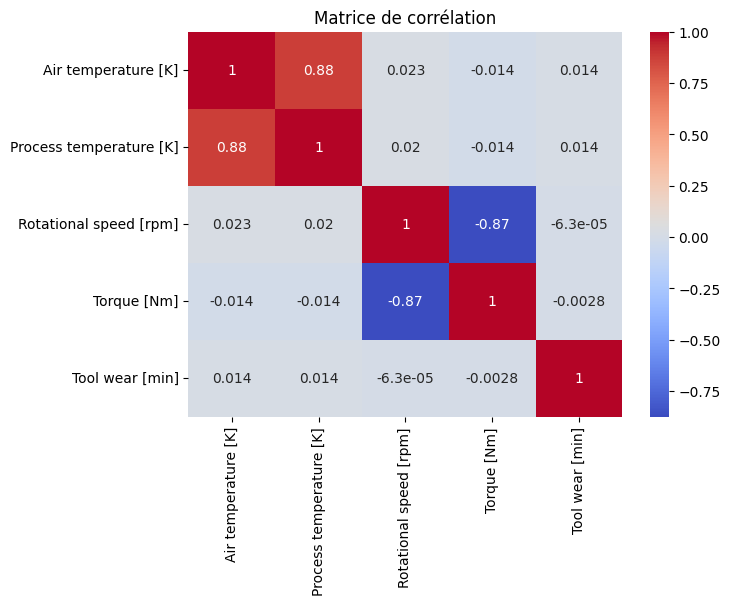

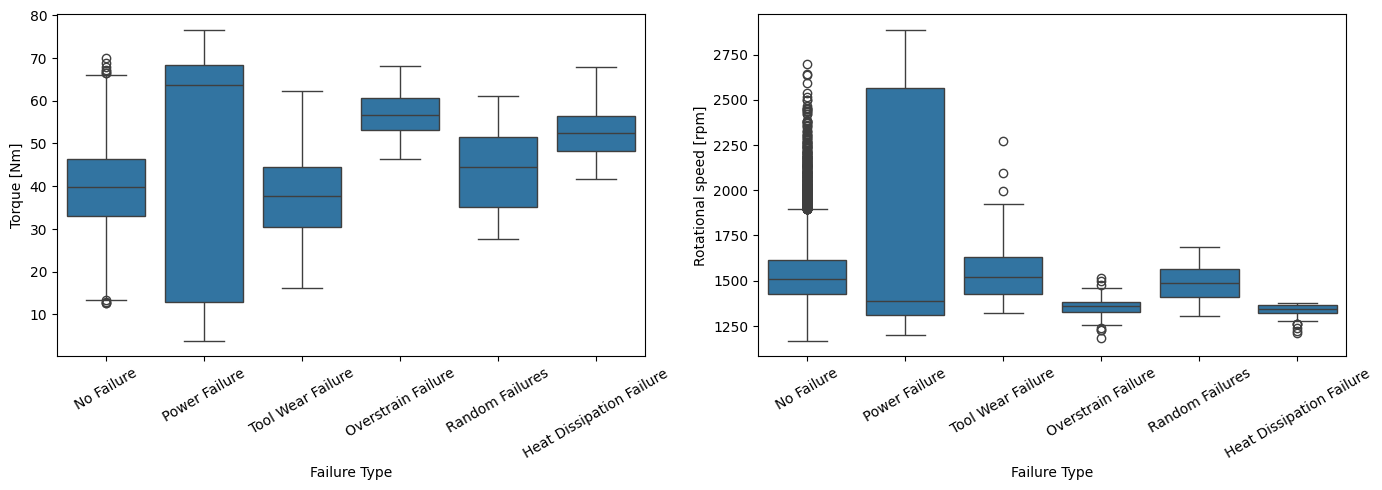

In [17]:
num_cols = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# Distribution des classes
plt.figure(figsize=(8, 4))
sns.countplot(y='Failure Type', data=df2, order=df2['Failure Type'].value_counts().index)
plt.title("Distribution des types de panne"); plt.show()

# Distribution des variables numériques
df2[num_cols].hist(figsize=(12, 7), bins=30)
plt.suptitle("Distribution des variables numériques"); plt.show()

# Corrélations
plt.figure(figsize=(7, 5))
sns.heatmap(df2[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Matrice de corrélation"); plt.show()

# Torque et vitesse de rotation selon le type de panne
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df2, x='Failure Type', y='Torque [Nm]', ax=ax[0])
sns.boxplot(data=df2, x='Failure Type', y='Rotational speed [rpm]', ax=ax[1])
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [18]:
from imblearn.over_sampling import SMOTE

num_cols = ['Air temperature [K]', 'Process temperature [K]',
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
feat_cols = ['Type'] + num_cols

Xc = df2[feat_cols].values.astype(np.float32)
yc = df2['label'].values

# 1. Séparation stratifiée (garde les proportions des classes dans train et test)
Xc_train_raw, Xc_test_raw, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=42)

print("Train avant SMOTE :", dict(zip(le.classes_, np.bincount(yc_train))))
print("Test              :", dict(zip(le.classes_, np.bincount(yc_test))))

# 2. SMOTE uniquement sur le train
smote = SMOTE(random_state=42, k_neighbors=3)
Xc_train_bal_raw, yc_train_bal = smote.fit_resample(Xc_train_raw, yc_train)
Xc_train_bal_raw[:, 0] = np.clip(np.round(Xc_train_bal_raw[:, 0]), 0, 2)   # Type reste entier

print("Train après SMOTE :", dict(zip(le.classes_, np.bincount(yc_train_bal))))

# 3. Normalisation : fit sur le train équilibré, appliqué à tout le reste
sc = StandardScaler()
Xc_train_bal = sc.fit_transform(Xc_train_bal_raw).astype(np.float32)
Xc_train = sc.transform(Xc_train_raw).astype(np.float32)   # train d'origine (pour évaluer)
Xc_test = sc.transform(Xc_test_raw).astype(np.float32)
yc_train_bal = yc_train_bal.astype(np.int64)

print(Xc_train_bal.shape, Xc_train.shape, Xc_test.shape)

Train avant SMOTE : {'Heat Dissipation Failure': np.int64(90), 'No Failure': np.int64(7714), 'Overstrain Failure': np.int64(62), 'Power Failure': np.int64(76), 'Random Failures': np.int64(14), 'Tool Wear Failure': np.int64(36)}
Test              : {'Heat Dissipation Failure': np.int64(22), 'No Failure': np.int64(1929), 'Overstrain Failure': np.int64(16), 'Power Failure': np.int64(19), 'Random Failures': np.int64(4), 'Tool Wear Failure': np.int64(9)}
Train après SMOTE : {'Heat Dissipation Failure': np.int64(7714), 'No Failure': np.int64(7714), 'Overstrain Failure': np.int64(7714), 'Power Failure': np.int64(7714), 'Random Failures': np.int64(7714), 'Tool Wear Failure': np.int64(7714)}
(46284, 6) (7992, 6) (1999, 6)


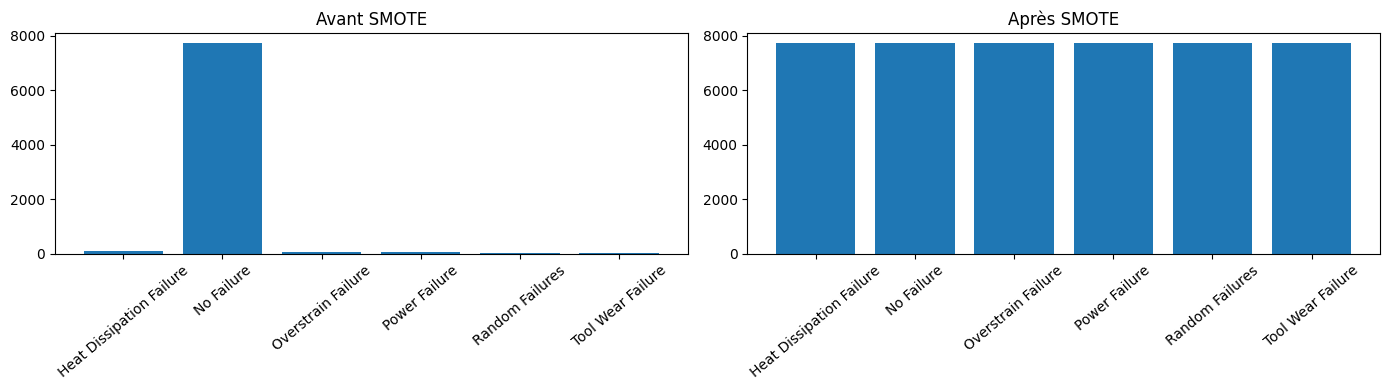

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(le.classes_, np.bincount(yc_train)); ax[0].set_title("Avant SMOTE")
ax[1].bar(le.classes_, np.bincount(yc_train_bal)); ax[1].set_title("Après SMOTE")
for a in ax: a.tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.show()

In [20]:
n_classes = len(le.classes_)

class MLPClf(nn.Module):
    def __init__(self, n_in=6, h1=64, h2=32, n_out=n_classes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = [nn.Linear(n_in, h1)]
        if batchnorm: layers.append(nn.BatchNorm1d(h1))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h1, h2)]
        if batchnorm: layers.append(nn.BatchNorm1d(h2))
        layers += [nn.ReLU(), nn.Dropout(dropout), nn.Linear(h2, n_out)]   # logits
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

print(MLPClf())

MLPClf(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [21]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import FunctionTransformer

netc = NeuralNetClassifier(
    MLPClf,
    criterion=nn.CrossEntropyLoss,
    optimizer=optim.Adam,
    max_epochs=30,
    batch_size=256,
    train_split=None,
    device=device,
    verbose=0,
)

pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('cast', FunctionTransformer(lambda X: X.astype(np.float32))),
    ('net', netc),
])

params_c = {
    'net__lr': [0.001, 0.01],
    'net__optimizer': [optim.Adam, optim.SGD],
    'net__max_epochs': [30, 60],
    'net__module__h1': [32, 64],
    'net__module__h2': [32],
}

from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

gsc = GridSearchCV(pipe, params_c, cv=cv, scoring='f1_macro', n_jobs=1, verbose=1)
gsc.fit(Xc_train, yc_train.astype(np.int64))   # train d'origine (non équilibré, déjà normalisé)

print("Meilleurs paramètres :", gsc.best_params_)
print("Meilleur F1 macro CV :", gsc.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Meilleurs paramètres : {'net__lr': 0.001, 'net__max_epochs': 60, 'net__module__h1': 64, 'net__module__h2': 32, 'net__optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur F1 macro CV : 0.3823263925980221


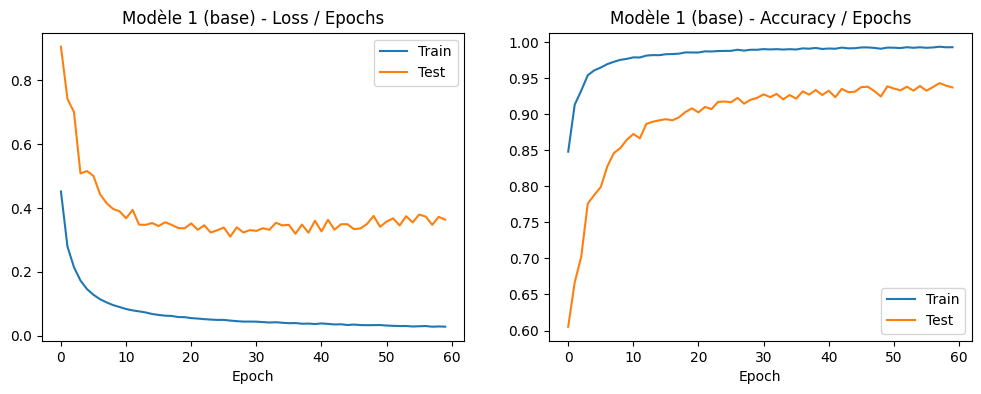

Accuracy train (équilibré) : 0.9927188158035278
Accuracy test              : 0.9369685053825378


In [22]:
bc = gsc.best_params_
h1c, h2c = bc['net__module__h1'], bc['net__module__h2']
lr_c, opt_cc, ep_c = bc['net__lr'], bc['net__optimizer'], bc['net__max_epochs']

def train_clf(model, lr, opt_class, epochs, wd=0.0, patience=None):
    model = model.to(device)
    opt = opt_class(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss()
    Xtr = torch.tensor(Xc_train_bal).to(device); ytr = torch.tensor(yc_train_bal, dtype=torch.long).to(device)
    Xte = torch.tensor(Xc_test).to(device);      yte = torch.tensor(yc_test, dtype=torch.long).to(device)
    hist = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    best, wait = 1e9, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            idx = perm[i:i+256]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            otr, ote = model(Xtr), model(Xte)
            lte = loss_fn(ote, yte).item()
            hist['train_loss'].append(loss_fn(otr, ytr).item()); hist['test_loss'].append(lte)
            hist['train_acc'].append((otr.argmax(1) == ytr).float().mean().item())
            hist['test_acc'].append((ote.argmax(1) == yte).float().mean().item())
        if patience:
            if lte < best:
                best, wait = lte, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    return model, hist

def plot_clf(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['train_loss'], label='Train'); ax[0].plot(h['test_loss'], label='Test')
    ax[0].set_title(f'{title} - Loss / Epochs'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h['train_acc'], label='Train'); ax[1].plot(h['test_acc'], label='Test')
    ax[1].set_title(f'{title} - Accuracy / Epochs'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()

c1, hc1 = train_clf(MLPClf(6, h1c, h2c), lr_c, opt_cc, ep_c)
plot_clf(hc1, "Modèle 1 (base)")
print("Accuracy train (équilibré) :", hc1['train_acc'][-1])
print("Accuracy test              :", hc1['test_acc'][-1])

,Train,Test
Accuracy,0.9602,0.9370
Sensibilité (recall macro),0.9910,0.6124
Précision macro,0.5969,0.4669
F1 macro,0.6843,0.5204
F1 pondéré,0.9712,0.9537


===== Train =====
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.71      1.00      0.83        90
              No Failure       1.00      0.96      0.98      7714
      Overstrain Failure       0.78      1.00      0.88        62
           Power Failure       0.76      0.99      0.86        76
         Random Failures       0.11      1.00      0.20        14
       Tool Wear Failure       0.22      1.00      0.36        36

                accuracy                           0.96      7992
               macro avg       0.60      0.99      0.68      7992
            weighted avg       0.99      0.96      0.97      7992



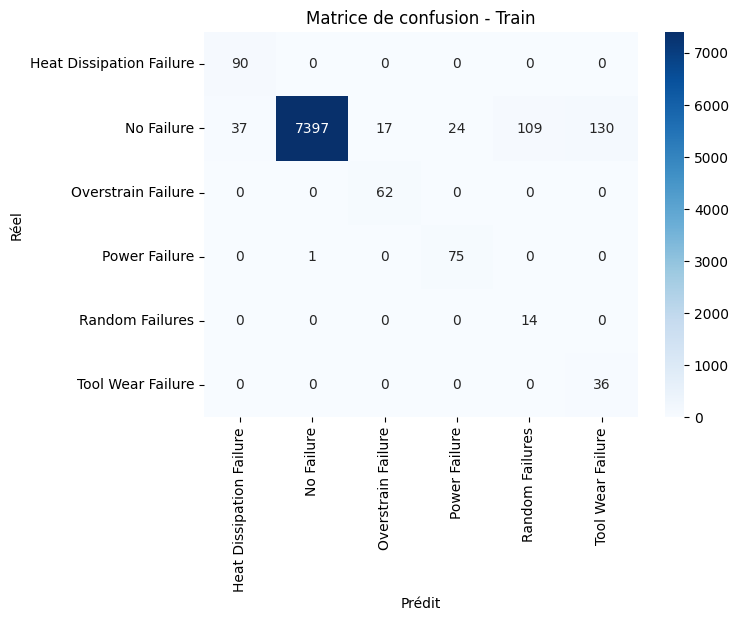

===== Test =====
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.55      0.95      0.70        22
              No Failure       0.99      0.94      0.97      1929
      Overstrain Failure       0.61      0.88      0.72        16
           Power Failure       0.62      0.79      0.70        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.02      0.11      0.04         9

                accuracy                           0.94      1999
               macro avg       0.47      0.61      0.52      1999
            weighted avg       0.97      0.94      0.95      1999



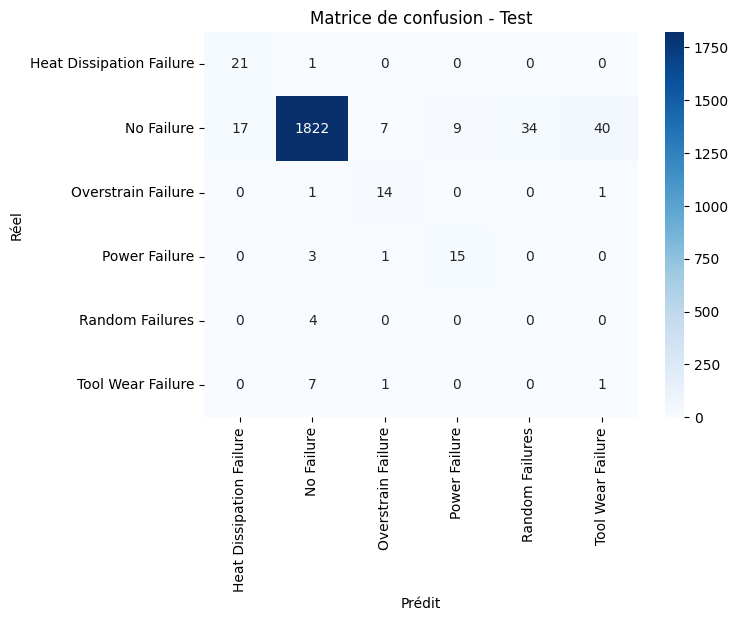

In [23]:
def get_preds(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X).to(device)).argmax(1).cpu().numpy()

def get_metrics(model, X, y):
    p = get_preds(model, X)
    return {
        'Accuracy': accuracy_score(y, p),
        'Sensibilité (recall macro)': recall_score(y, p, average='macro', zero_division=0),
        'Précision macro': precision_score(y, p, average='macro', zero_division=0),
        'F1 macro': f1_score(y, p, average='macro', zero_division=0),
        'F1 pondéré': f1_score(y, p, average='weighted', zero_division=0),
    }

def evaluate(model, X, y, name):
    p = get_preds(model, X)
    print(f"===== {name} =====")
    print(classification_report(y, p, labels=range(n_classes),
                                target_names=le.classes_, zero_division=0))
    plt.figure(figsize=(7, 5))
    sns.heatmap(confusion_matrix(y, p, labels=range(n_classes)), annot=True, fmt='d',
                cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.show()

# Tableau récapitulatif train vs test
res = pd.DataFrame({
    'Train': get_metrics(c1, Xc_train, yc_train),
    'Test': get_metrics(c1, Xc_test, yc_test),
}).round(4)
display(res)

evaluate(c1, Xc_train, yc_train, "Train")
evaluate(c1, Xc_test, yc_test, "Test")

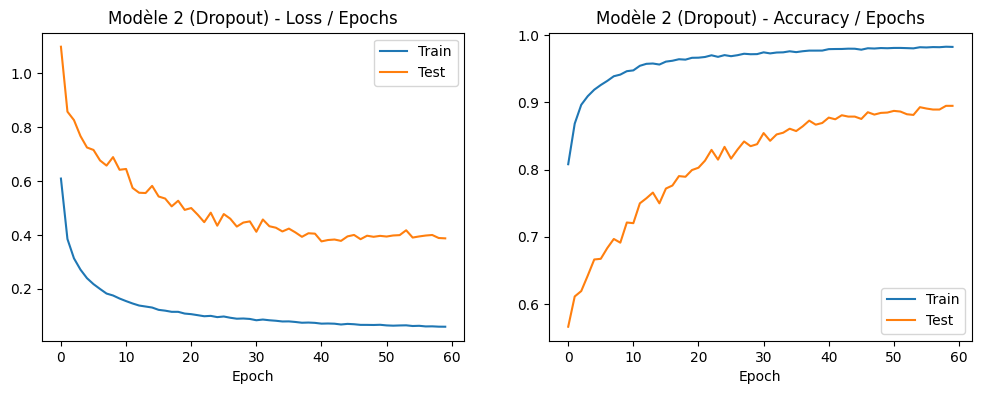

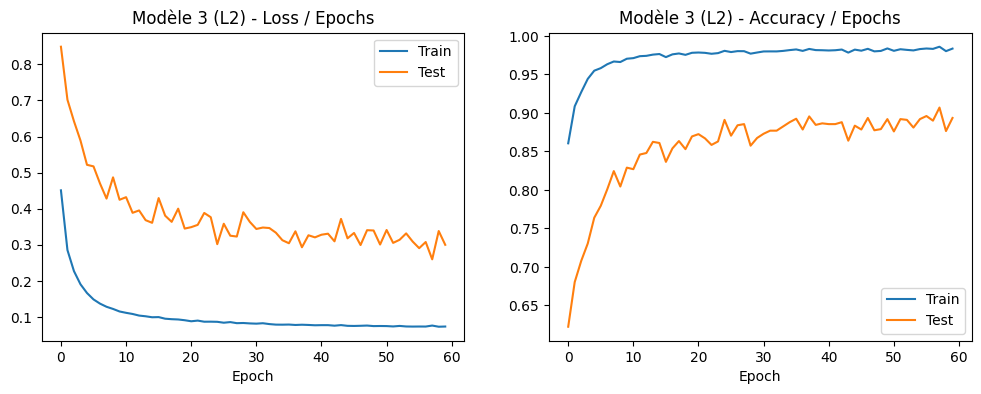

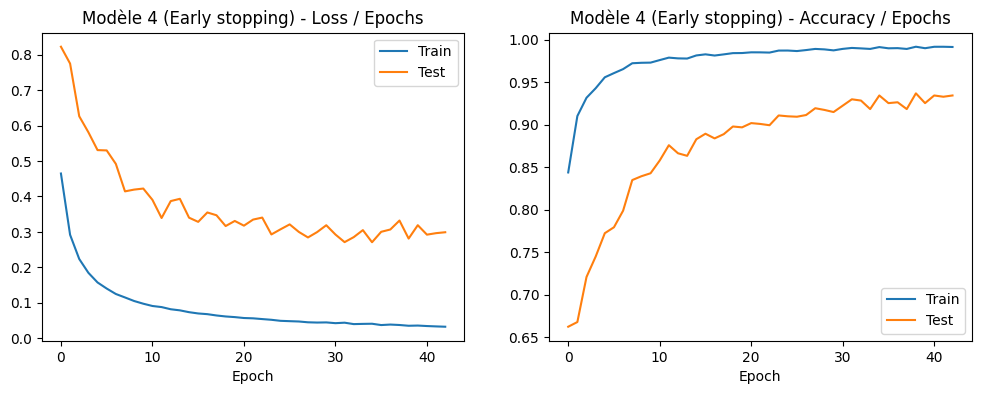

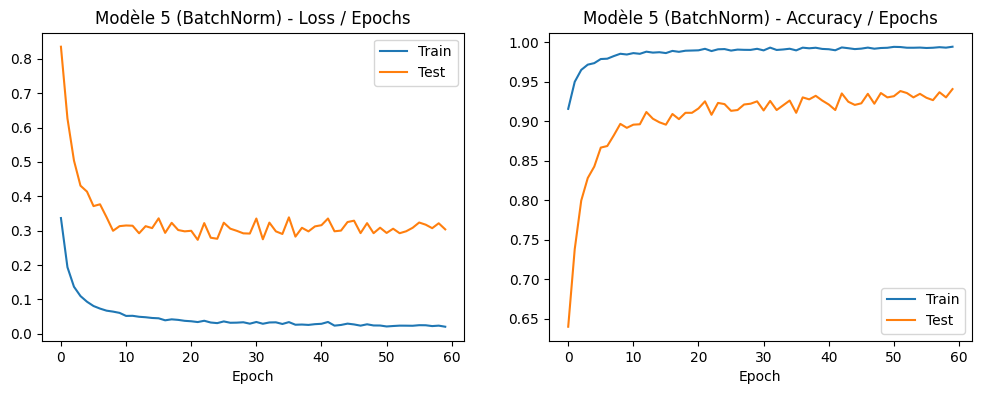

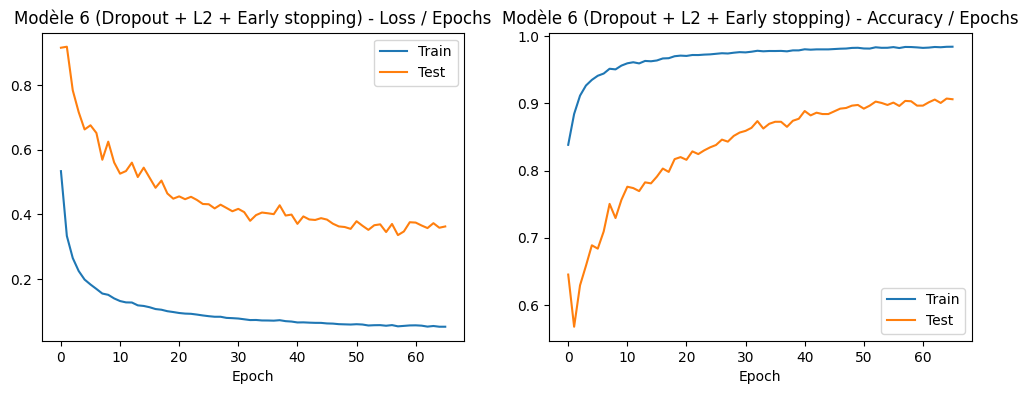

In [24]:
# Modèle 2 : Dropout seul
c2, hc2 = train_clf(MLPClf(6, h1c, h2c, dropout=0.3), lr_c, opt_cc, ep_c)

# Modèle 3 : L2 (weight decay) seul
c3, hc3 = train_clf(MLPClf(6, h1c, h2c), lr_c, opt_cc, ep_c, wd=1e-3)

# Modèle 4 : Early stopping seul
c4, hc4 = train_clf(MLPClf(6, h1c, h2c), lr_c, opt_cc, 150, patience=8)

# Modèle 5 : BatchNorm seule
c5, hc5 = train_clf(MLPClf(6, h1c, h2c, batchnorm=True), lr_c, opt_cc, ep_c)

# Modèle 6 : Combinaison Dropout + L2 + Early stopping
c6, hc6 = train_clf(MLPClf(6, h1c, h2c, dropout=0.2), lr_c, opt_cc, 150, wd=1e-4, patience=8)

plot_clf(hc2, "Modèle 2 (Dropout)")
plot_clf(hc3, "Modèle 3 (L2)")
plot_clf(hc4, "Modèle 4 (Early stopping)")
plot_clf(hc5, "Modèle 5 (BatchNorm)")
plot_clf(hc6, "Modèle 6 (Dropout + L2 + Early stopping)")

,Modèle,Epochs,Accuracy test,Recall macro test,F1 macro test,F1 macro train,Écart F1 (train-test)
0,Base (modèle 1),60,0.9370,0.6124,0.5204,0.6843,0.1639
1,Dropout,60,0.8949,0.6577,0.4885,0.5545,0.0660
2,L2,60,0.8934,0.6418,0.4639,0.5518,0.0879
3,Early stopping,43,0.9345,0.6488,0.5349,0.6633,0.1284
4,BatchNorm,60,0.9405,0.5549,0.4842,0.7137,0.2295
5,Combiné,66,0.9060,0.6574,0.5089,0.5766,0.0677


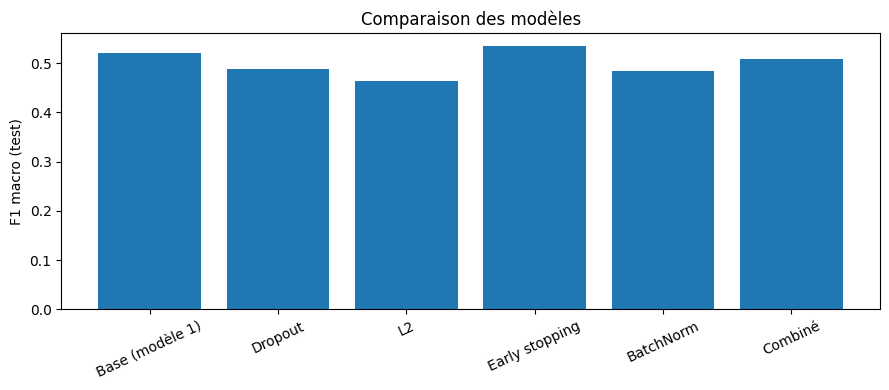

In [25]:
models = {
    'Base (modèle 1)': (c1, hc1),
    'Dropout': (c2, hc2),
    'L2': (c3, hc3),
    'Early stopping': (c4, hc4),
    'BatchNorm': (c5, hc5),
    'Combiné': (c6, hc6),
}

rows = []
for name, (m, h) in models.items():
    mt = get_metrics(m, Xc_test, yc_test)
    mtr = get_metrics(m, Xc_train, yc_train)
    rows.append({
        'Modèle': name,
        'Epochs': len(h['train_loss']),
        'Accuracy test': mt['Accuracy'],
        'Recall macro test': mt['Sensibilité (recall macro)'],
        'F1 macro test': mt['F1 macro'],
        'F1 macro train': mtr['F1 macro'],
        'Écart F1 (train-test)': mtr['F1 macro'] - mt['F1 macro'],
    })
comparaison_c = pd.DataFrame(rows).round(4)
display(comparaison_c)

plt.figure(figsize=(9, 4))
plt.bar(comparaison_c['Modèle'], comparaison_c['F1 macro test'])
plt.ylabel('F1 macro (test)'); plt.title('Comparaison des modèles')
plt.xticks(rotation=25); plt.tight_layout(); plt.show()